# Comparacao entre NASA POWER, INPE e SONDA

Este notebook e exclusivamente para comparacoes entre fontes. Os processamentos e as figuras historicas individuais estao nos notebooks `visualizar_base_nasa_power.ipynb`, `visualizar_base_inpe.ipynb` e `visualizar_base_sonda.ipynb`.

Todas as comparacoes sao recortadas explicitamente para 28/08/2024 11h a 11/02/2025 9h. Radiacao compara NASA POWER, INPE e SONDA-SD; temperatura e umidade comparam NASA POWER, INPE e SONDA-MD.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['savefig.dpi'] = 180

def encontrar_pasta_2026(inicio=Path.cwd()):
    inicio = inicio.resolve()
    for pasta in (inicio, *inicio.parents):
        candidata = pasta / '2026'
        if candidata.exists():
            return candidata
    raise FileNotFoundError('Nao foi encontrada a pasta 2026 a partir do diretorio atual.')

PASTA_2026 = encontrar_pasta_2026()
PASTA_NASA = PASTA_2026 / 'dados_brutos_nasa_power'
PASTA_SONDA_TRATADA = PASTA_2026 / 'dados_tratados_sonda'
PASTA_SAIDA = PASTA_2026 / 'visualizacoes_comparativas_bases'
PASTA_COMPARACAO = PASTA_SAIDA / 'comparacao_entre_fontes'
PASTA_TABELAS = PASTA_SAIDA / 'tabelas'
for pasta in (PASTA_COMPARACAO, PASTA_TABELAS):
    pasta.mkdir(parents=True, exist_ok=True)

ARQUIVO_INPE = PASTA_SAIDA / 'dados_padronizados' / 'inpe_2024-08-28_11h_continua_umidade_tratada.csv'
INICIO_COMPARACAO = pd.Timestamp('2024-08-28 11:00:00')
FIM_COMPARACAO = pd.Timestamp('2025-02-11 09:00:00')
INVALIDOS = [-9999, -999, -6999, 7999, 9999]
FREQUENCIA_VISUAL = 'D'
ROTULOS = {
    'radiacao_onda_curta': 'Radiacao de onda curta (W/m2)',
    'temperatura': 'Temperatura (C)',
    'umidade_relativa': 'Umidade relativa (%)',
}

def recortar_comparacao(dados):
    return dados.loc[
        (dados['data_hora'] >= INICIO_COMPARACAO)
        & (dados['data_hora'] <= FIM_COMPARACAO)
    ].copy().reset_index(drop=True)

def converter_numericas(df, colunas):
    for coluna in colunas:
        if coluna in df.columns:
            df[coluna] = pd.to_numeric(df[coluna], errors='coerce').replace(INVALIDOS, np.nan)
    return df

def ler_nasa_power():
    partes = []
    for arquivo in sorted(PASTA_NASA.glob('*.csv')):
        linhas = arquivo.read_text(encoding='utf-8').splitlines()
        cabecalho = next(i for i, linha in enumerate(linhas) if linha.startswith('YEAR,'))
        bruto = pd.read_csv(arquivo, skiprows=cabecalho)
        bruto = converter_numericas(bruto, ['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M'])
        bruto['data_hora'] = pd.to_datetime(bruto[['YEAR', 'MO', 'DY', 'HR']].rename(columns={'YEAR': 'year', 'MO': 'month', 'DY': 'day', 'HR': 'hour'}))
        partes.append(bruto[['data_hora', 'ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M']])
    dados = pd.concat(partes, ignore_index=True).rename(columns={'ALLSKY_SFC_SW_DWN': 'radiacao_onda_curta', 'T2M': 'temperatura', 'RH2M': 'umidade_relativa'})
    return recortar_comparacao(dados.sort_values('data_hora').drop_duplicates('data_hora'))

def ler_inpe():
    dados = pd.read_csv(ARQUIVO_INPE, parse_dates=['data_hora'])
    dados = converter_numericas(dados, ['radiacao_onda_curta', 'temperatura', 'umidade_relativa'])
    return recortar_comparacao(dados.dropna(subset=['data_hora']).sort_values('data_hora').drop_duplicates('data_hora'))

def ler_sonda(nome_arquivo, coluna):
    dados = pd.read_csv(PASTA_SONDA_TRATADA / nome_arquivo, parse_dates=['data_hora'])
    dados[coluna] = pd.to_numeric(dados[coluna], errors='coerce')
    return recortar_comparacao(dados.dropna(subset=['data_hora']).sort_values('data_hora').drop_duplicates('data_hora'))

nasa = ler_nasa_power()
inpe = ler_inpe()
sonda_md = ler_sonda('sonda_md_horario_padronizado.csv', 'temperatura')
sonda_sd = ler_sonda('sonda_sd_depois_lacuna.csv', 'radiacao_onda_curta')
print(f'Periodo explicitamente comparado: {INICIO_COMPARACAO} a {FIM_COMPARACAO}')


Periodo explicitamente comparado: 2024-08-28 11:00:00 a 2025-02-11 09:00:00


## Comparacoes e estatisticas

Cada tabela usa somente horarios com valores validos nas tres fontes da respectiva variavel.


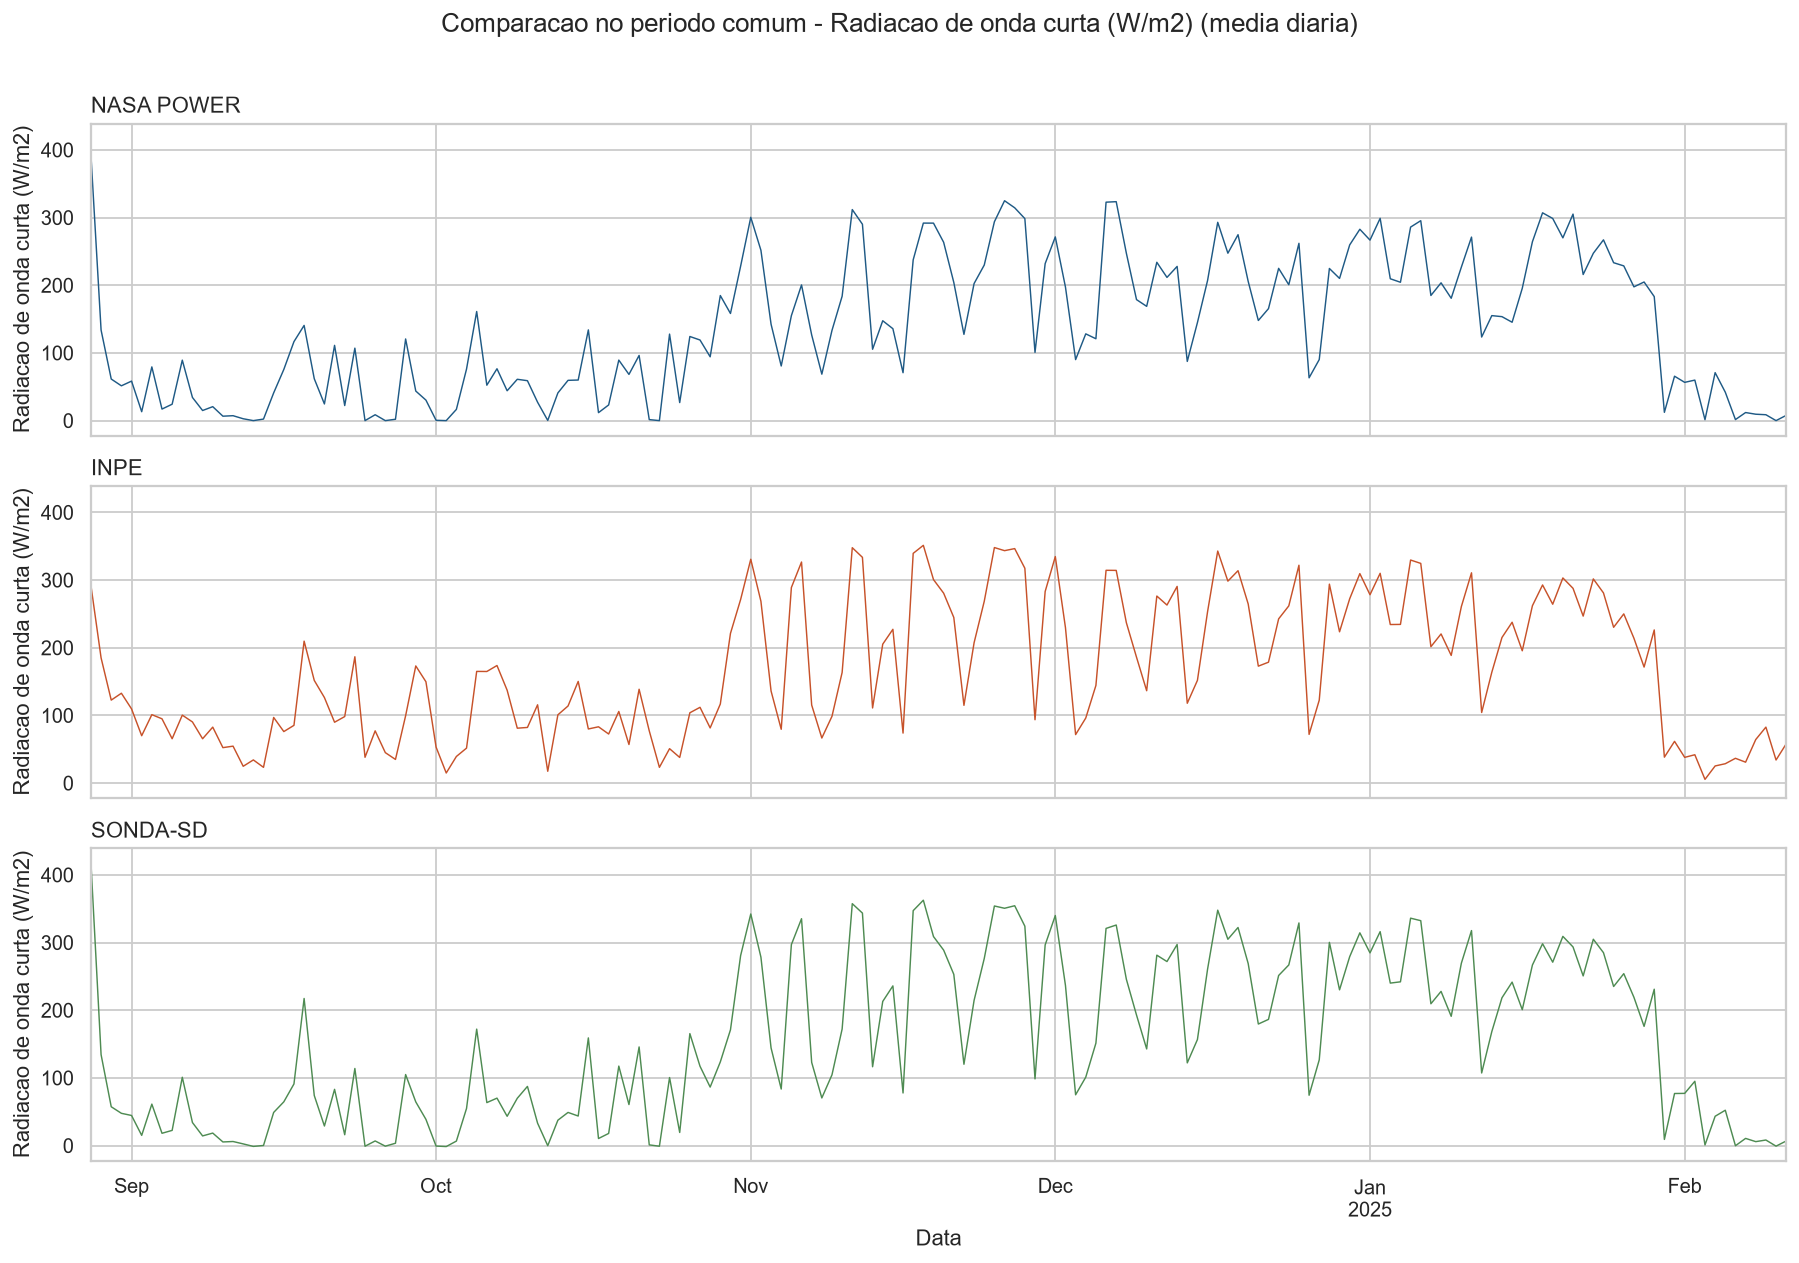

radiacao_onda_curta: 2024-08-28 11:00:00 a 2025-02-11 09:00:00 | 3420 horas comuns


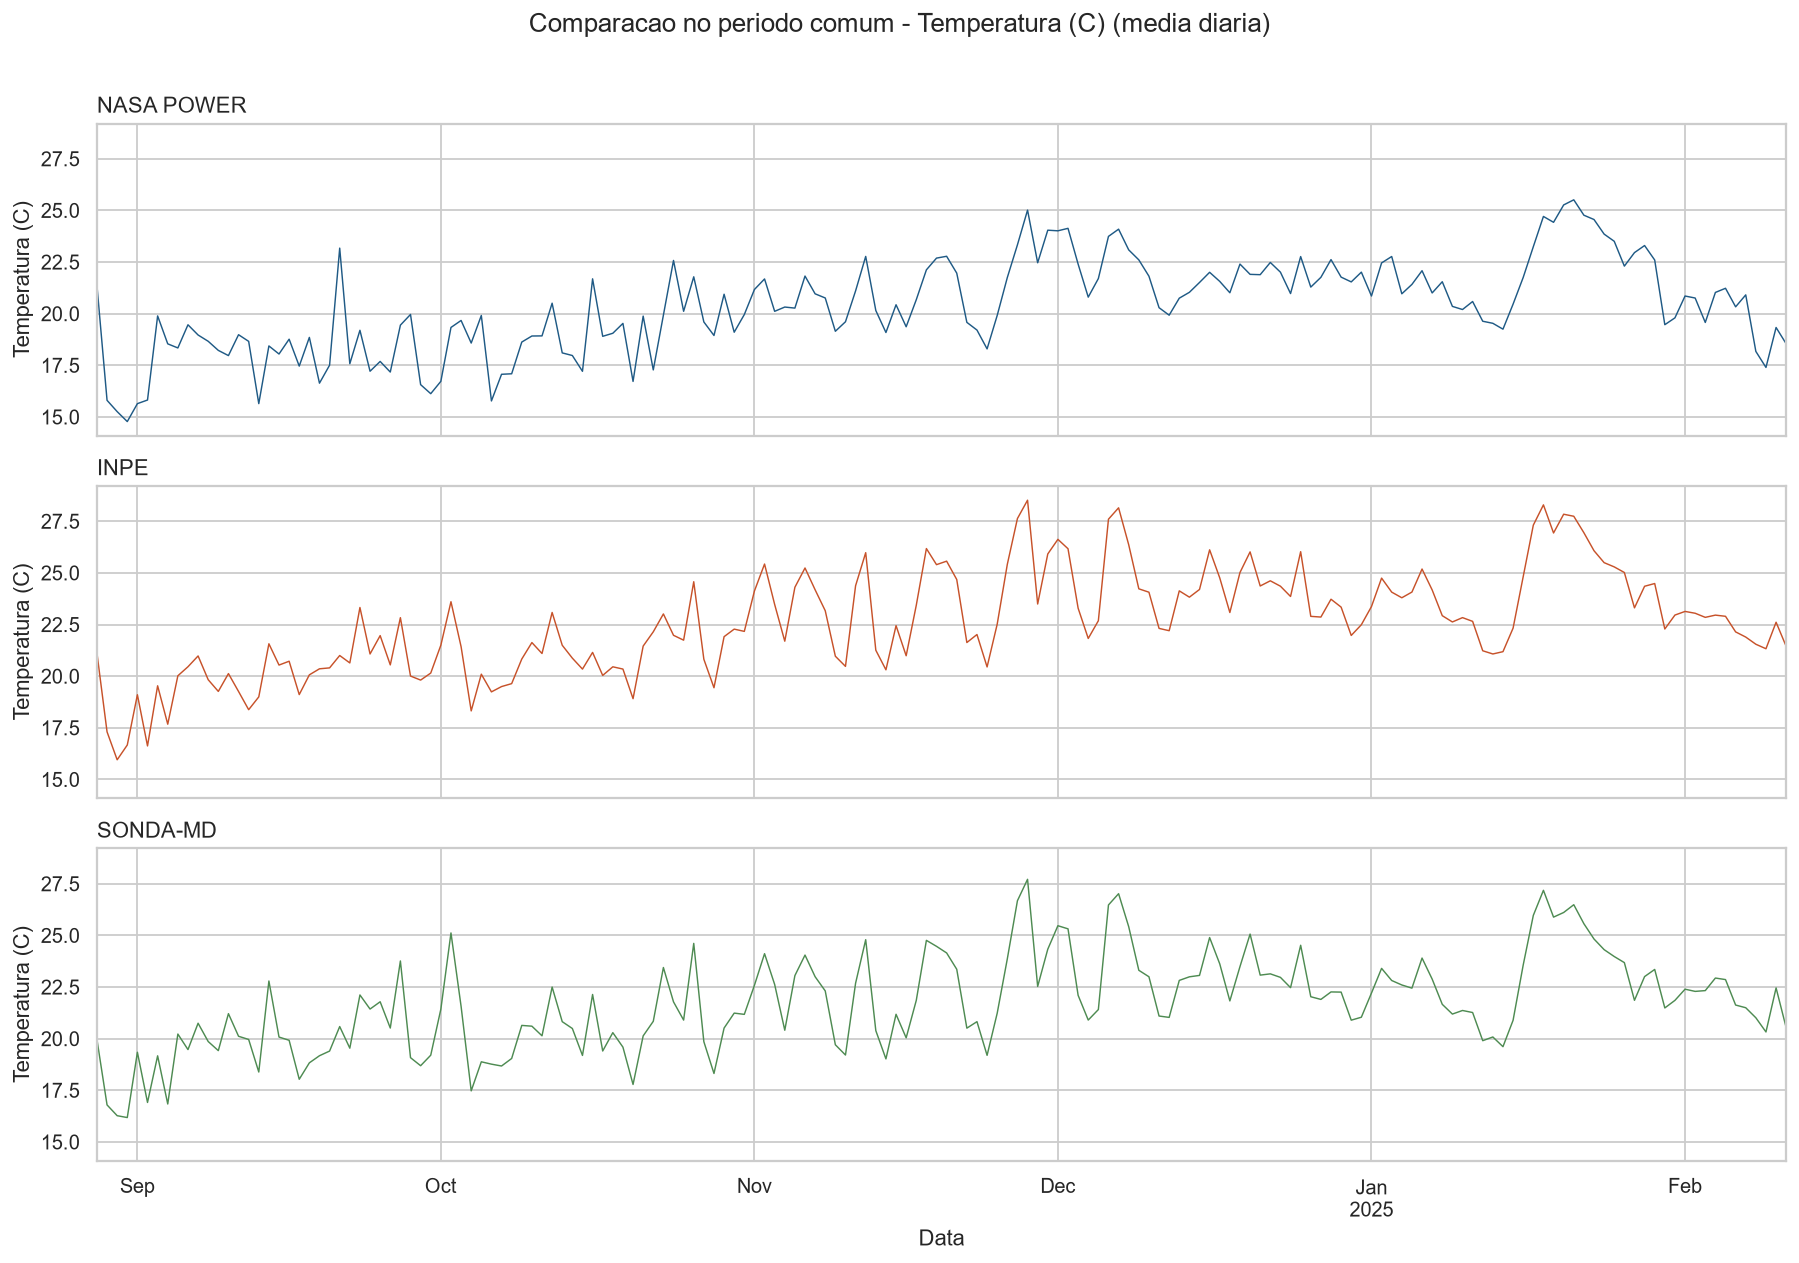

temperatura: 2024-08-28 11:00:00 a 2025-02-11 09:00:00 | 3420 horas comuns


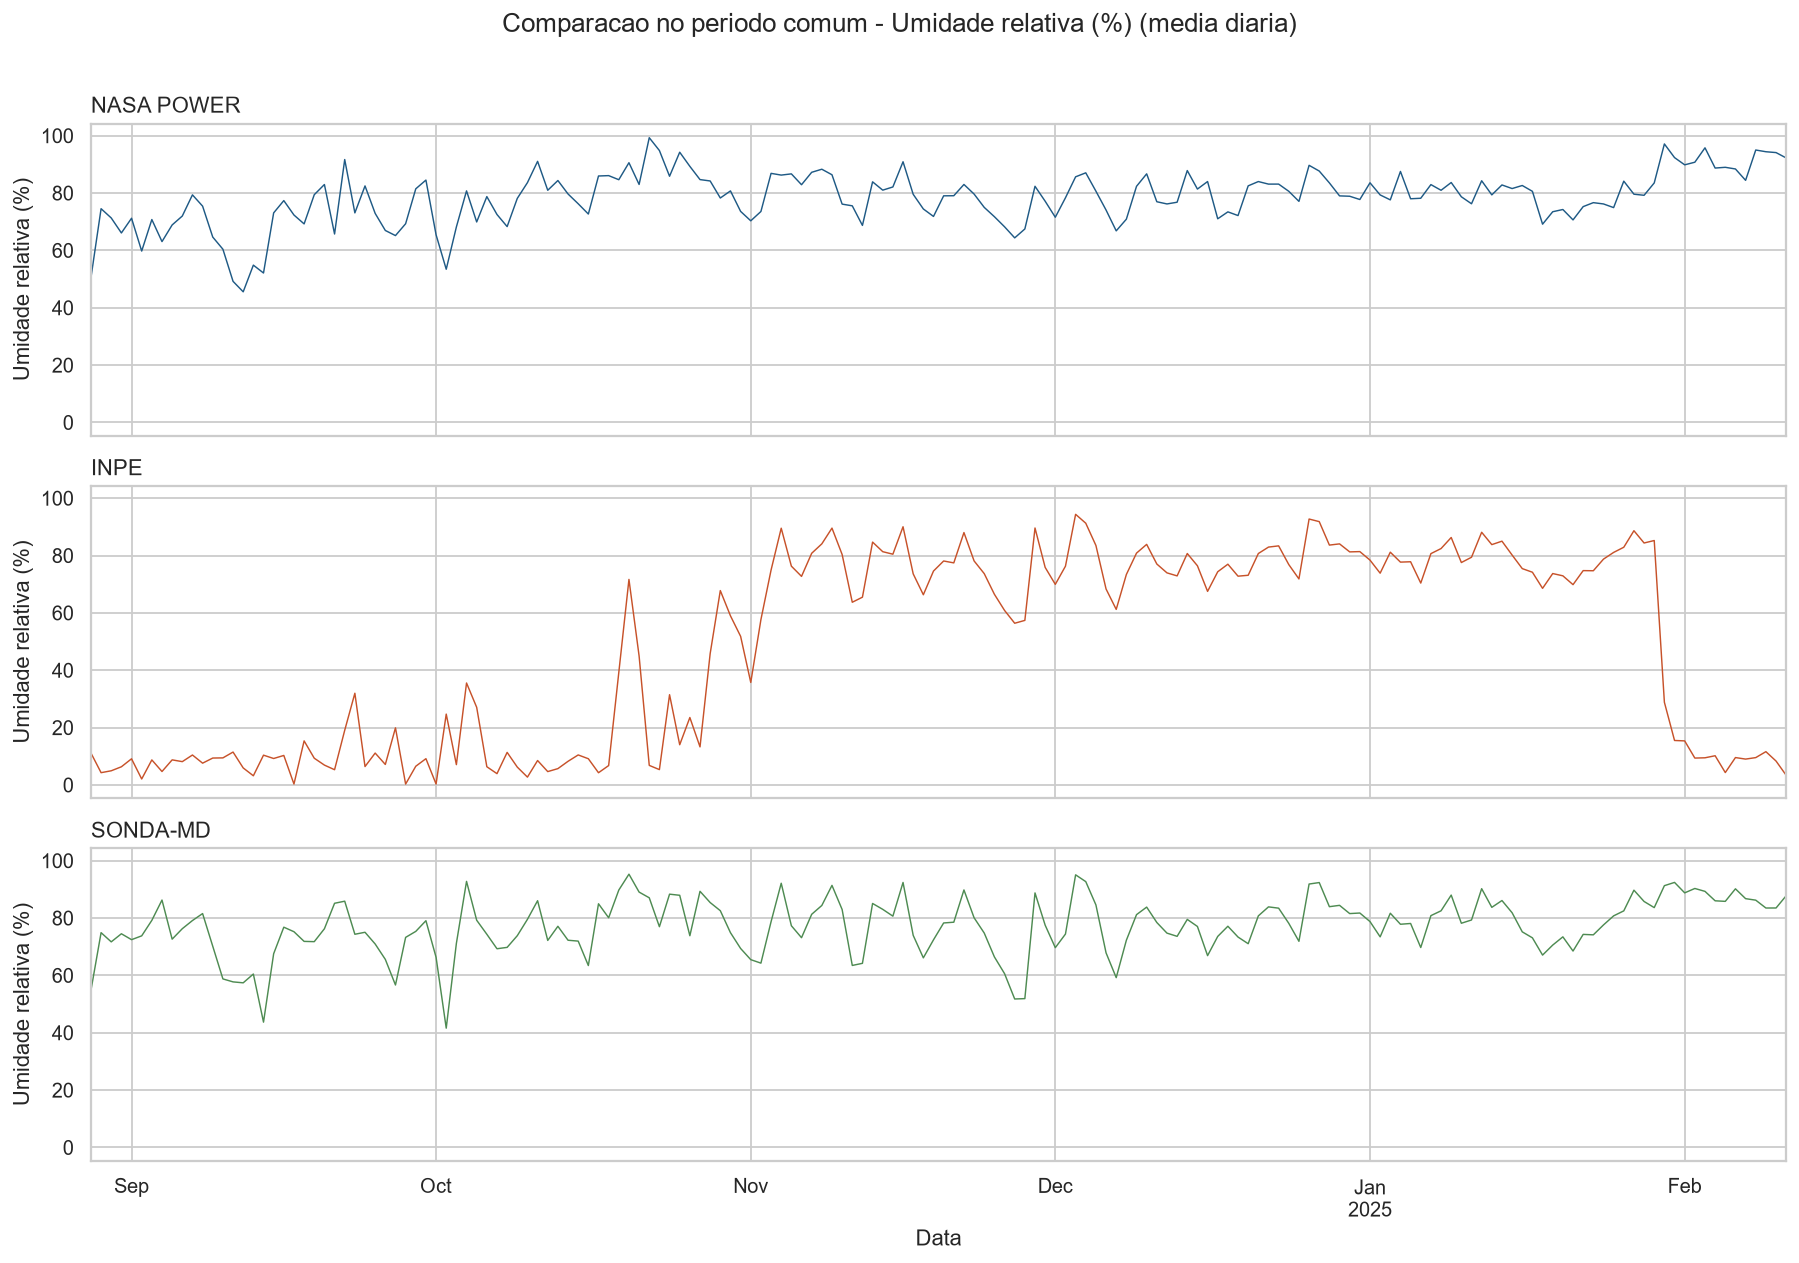

umidade_relativa: 2024-08-28 11:00:00 a 2025-02-11 09:00:00 | 3420 horas comuns


In [2]:
def montar_comparacao(variavel, fontes):
    partes = [dados[['data_hora', coluna]].rename(columns={coluna: rotulo}) for rotulo, (dados, coluna) in fontes.items()]
    comparacao = partes[0]
    for parte in partes[1:]:
        comparacao = comparacao.merge(parte, on='data_hora', how='inner')
    comparacao = comparacao.dropna().sort_values('data_hora').reset_index(drop=True)
    if comparacao.empty:
        raise ValueError(f'Sem periodo comum com dados validos para {variavel}. Verifique os dados e os fusos horarios.')
    comparacao.to_csv(PASTA_COMPARACAO / f'comparacao_{variavel}.csv', index=False)
    return comparacao

def estatisticas(comparacao, variavel):
    return pd.DataFrame([{
        'variavel': variavel, 'fonte': fonte, 'n_horas_comuns': len(comparacao),
        'inicio_comum': comparacao.data_hora.min(), 'fim_comum': comparacao.data_hora.max(),
        'media': comparacao[fonte].mean(), 'mediana': comparacao[fonte].median(),
        'desvio_padrao': comparacao[fonte].std(), 'minimo': comparacao[fonte].min(),
        'maximo': comparacao[fonte].max(),
        'percentil_25': comparacao[fonte].quantile(.25), 'percentil_75': comparacao[fonte].quantile(.75),
    } for fonte in comparacao.columns.drop('data_hora')])

def plotar_comparacao(comparacao, variavel, arquivo):
    fontes = comparacao.columns.drop('data_hora').tolist()
    diario = comparacao.set_index('data_hora')[fontes].resample(FREQUENCIA_VISUAL).mean()
    fig, eixos = plt.subplots(len(fontes), 1, figsize=(14, 3.2 * len(fontes)), sharex=True, sharey=True)
    if len(fontes) == 1:
        eixos = [eixos]
    for eixo, fonte, cor in zip(eixos, fontes, ['#1f5a85', '#c7522a', '#4e8b52']):
        diario[fonte].plot(ax=eixo, color=cor, linewidth=0.8)
        eixo.set_ylabel(ROTULOS.get(variavel, variavel))
        eixo.set_title(fonte, loc='left')
    eixos[-1].set_xlabel('Data')
    fig.suptitle(f'Comparacao no periodo comum - {ROTULOS[variavel]} (media diaria)', y=1.01)
    fig.tight_layout()
    fig.savefig(arquivo, bbox_inches='tight')
    plt.show()
    plt.close(fig)

CONFIGURACOES = {
    'radiacao_onda_curta': {'NASA POWER': (nasa, 'radiacao_onda_curta'), 'INPE': (inpe, 'radiacao_onda_curta'), 'SONDA-SD': (sonda_sd, 'radiacao_onda_curta')},
    'temperatura': {'NASA POWER': (nasa, 'temperatura'), 'INPE': (inpe, 'temperatura'), 'SONDA-MD': (sonda_md, 'temperatura')},
    'umidade_relativa': {'NASA POWER': (nasa, 'umidade_relativa'), 'INPE': (inpe, 'umidade_relativa'), 'SONDA-MD': (sonda_md, 'umidade_relativa')},
}

tabelas = []
for variavel, fontes in CONFIGURACOES.items():
    comparacao = montar_comparacao(variavel, fontes)
    plotar_comparacao(comparacao, variavel, PASTA_COMPARACAO / f'comparacao_{variavel}.png')
    tabela = estatisticas(comparacao, variavel)
    tabela.to_csv(PASTA_TABELAS / f'estatisticas_{variavel}.csv', index=False)
    tabelas.append(tabela)
    print(f'{variavel}: {comparacao.data_hora.min()} a {comparacao.data_hora.max()} | {len(comparacao)} horas comuns')

pd.concat(tabelas, ignore_index=True).to_csv(PASTA_TABELAS / 'estatisticas_descritivas_todas_as_fontes.csv', index=False)


## Correlacoes entre as fontes


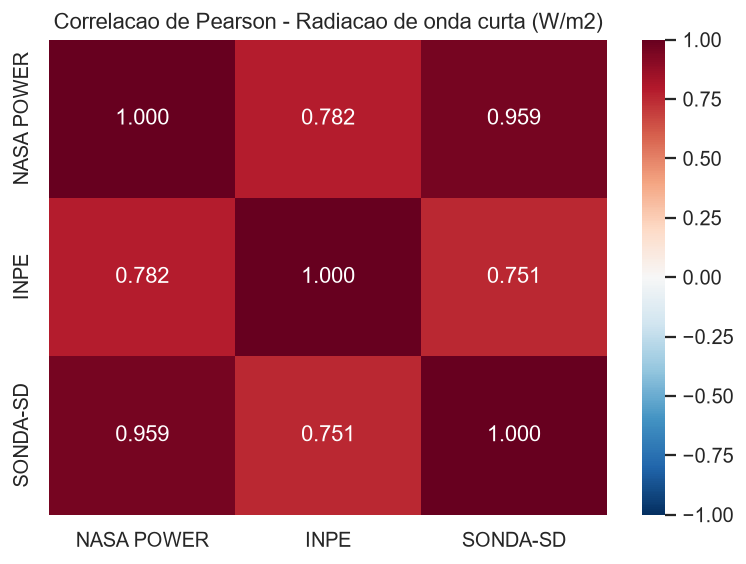

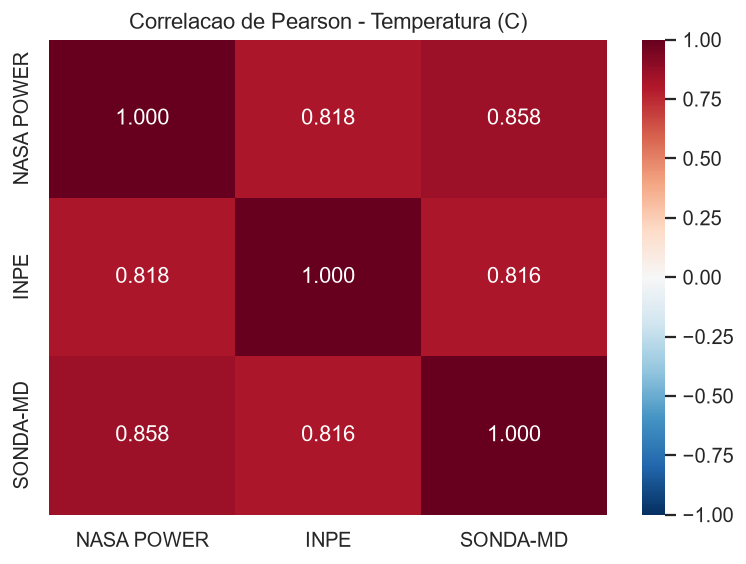

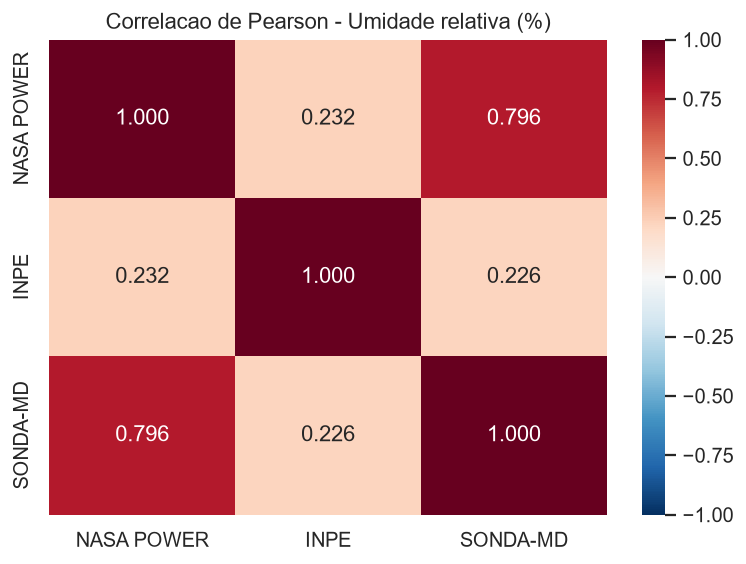

In [3]:
for variavel in CONFIGURACOES:
    comparacao = pd.read_csv(PASTA_COMPARACAO / f'comparacao_{variavel}.csv', parse_dates=['data_hora'])
    correlacao = comparacao.drop(columns='data_hora').corr(method='pearson')
    correlacao.to_csv(PASTA_TABELAS / f'correlacao_{variavel}.csv')
    fig, ax = plt.subplots(figsize=(6, 4.5))
    sns.heatmap(correlacao, annot=True, fmt='.3f', vmin=-1, vmax=1, cmap='RdBu_r', ax=ax)
    ax.set_title(f'Correlacao de Pearson - {ROTULOS[variavel]}')
    fig.tight_layout()
    fig.savefig(PASTA_COMPARACAO / f'correlacao_{variavel}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)
